# Mask R-CNN – zero-shot on FoodSeg103

Outputs: `outputs/maskrcnn_{val,test}.pkl` (fine-tuned) and `outputs/maskrcnn_zeroshot_{val,test}.pkl` (zero-shot) for
`compare_models.ipynb`; checkpoints and sweeps in `runs/exp3/`

## 2. Mask R-CNN Architecture — The Full Pipeline

Mask R-CNN (He et al., ICCV 2017) extends Faster R-CNN by adding a parallel mask prediction branch:

```
Input Image
    │
    ▼
┌──────────────────┐
│  BACKBONE        │  ResNet-50 or ResNet-101
│  + FPN           │  Feature Pyramid Network: features at 5 scales
└──────────────────┘
    │  feature maps at scales P2–P6
    ▼
┌──────────────────┐
│  RPN             │  Region Proposal Network
│  (anchors)       │  Slides 3 anchor sizes × 3 ratios over each scale
│                  │  → ~100,000 candidate boxes → NMS → ~1,000 proposals
└──────────────────┘
    │  ~1,000 region proposals (RoIs)
    ▼
┌──────────────────┐
│  RoI Align       │  Crops + bilinearly interpolates feature map
│                  │  Each proposal → fixed 7×7 or 14×14 feature grid
└──────────────────┘
    │  fixed-size feature crops
    ├──────────────────────────────────┐
    ▼                                  ▼
┌─────────────────┐        ┌───────────────────┐
│  Box head       │        │  Mask head        │
│  FC layers      │        │  4× conv layers   │
│  → class label  │        │  → 28×28 binary   │
│  → box delta    │        │     mask per class│
└─────────────────┘        └───────────────────┘
```

**Three simultaneous losses during training:**
- `L_cls` — cross-entropy on class prediction
- `L_box` — smooth-L1 on bounding box regression
- `L_mask` — binary cross-entropy on the 28×28 mask (only for the GT class)

`L_total = L_cls + L_box + L_mask`

The mask branch only trains on the correct class's mask — it predicts a mask for every class but only the GT class mask contributes to the loss. This decouples mask quality from classification.

## 1 Library

In [16]:
# Mask R-CNN for food image segmentation
import sys, platform, json, math, random, time
from pathlib import Path

# general utilities and system information
import cv2
import numpy as np
import torch
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# shared dataset access + evaluation (playground/foodseg_common.py)
import foodseg_common as fc

## 2 Configuration

In [ ]:
# paths
PROJECT_ROOT = fc.PROJECT_ROOT
DATA_ROOT = fc.DATA_ROOT
RUN_NAME = 'exp3'
RUN_DIR = fc.PLAYGROUND / 'runs' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
OUT_ROOT = fc.OUT_ROOT
OUT_ROOT.mkdir(parents=True, exist_ok=True)

# hyper-parameters
CFG = dict(
    arch='v2',
    epochs=10,
    batch_size=2,
    lr=5e-4,
    min_size=640,
    max_size=1024,
    seed=42,
    num_workers=0,
    min_area=fc.MIN_AREA,
    max_dets=30,
    nms_thresh=0.6,
    score_thresh=0.05,
    use_food_preprocess=True,
)

# Set device for training and inference
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('device:', device)
print('project_root:', PROJECT_ROOT)
print('data_root:', DATA_ROOT)
print('run_dir:', RUN_DIR)
for name in fc.SPLITS:
    print(f'  {name}: {len(fc.read_split_ids(name))} ids')

device: cuda
project_root: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1
data_root: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\dataset\foodseg103
run_dir: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\exp3
  train: 4982 ids
  val: 1067 ids
  test: 1069 ids


## 3 Dataset, model, training loop, and evaluation

### 3a Dataset

In [11]:
# for data preprocessing and loading
from torchvision import tv_tensors
from torchvision.transforms import v2 as T
from torch.utils.data import DataLoader


def _get_transforms(augment: bool):
    """Get the composed transformations for the dataset."""
    ops = []
    if augment:
        ops += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.85, 1.15)),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.02),
        ]
    ops += [T.ToDtype(torch.float32, scale=True), T.SanitizeBoundingBoxes(min_size=4)]
    return T.Compose(ops)


class FoodDataset(torch.utils.data.Dataset):
    """FoodSeg103 dataset converted to pseudo-instance targets for Mask R-CNN."""

    def __init__(self, split, augment=False, min_area=100, limit=None, use_food_preprocess=False):
        self.split = split
        self.min_area = min_area
        ids = fc.read_split_ids(split)
        self.ids = ids[:limit] if limit else ids
        self.transform = _get_transforms(augment)
        self.use_food_preprocess = use_food_preprocess

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        sample_id = self.ids[idx]
        rgb = fc.load_rgb(fc.image_path(self.split, sample_id), preprocess=self.use_food_preprocess)
        mask_arr = fc.load_label_mask(fc.mask_path(self.split, sample_id))
        h, w = mask_arr.shape

        # Build one instance per class-id region (excluding 0 background).
        inst = fc.gt_instances(mask_arr, self.min_area)
        if len(inst):
            boxes = []
            for m in inst:
                ys, xs = np.nonzero(m)
                boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
            masks_t = torch.from_numpy(inst.astype(np.uint8))
            boxes_t = torch.tensor(boxes, dtype=torch.float32)
            labels_t = torch.ones(len(inst), dtype=torch.int64)
        else:
            masks_t = torch.zeros((0, h, w), dtype=torch.uint8)
            boxes_t = torch.zeros((0, 4), dtype=torch.float32)
            labels_t = torch.zeros((0,), dtype=torch.int64)

        img_t = tv_tensors.Image(torch.from_numpy(rgb).permute(2, 0, 1).contiguous())
        target = {
            'boxes': tv_tensors.BoundingBoxes(boxes_t, format='XYXY', canvas_size=(h, w)),
            'masks': tv_tensors.Mask(masks_t),
            'labels': labels_t,
            'image_id': torch.tensor([idx], dtype=torch.int64),
        }
        return self.transform(img_t, target)


def collate_fn(batch):
    return tuple(zip(*batch))


def _targets_to_device(targets, dev):
    """Move target dicts to device, stripping tv_tensor wrappers."""
    out = []
    required = ('boxes', 'masks', 'labels')
    for i, t in enumerate(targets):
        missing = [k for k in required if k not in t]
        if missing:
            raise KeyError(
                f"Target at index {i} is missing keys {missing}. "
                f"Available keys: {list(t.keys())}"
            )
        out.append({
            'boxes': t['boxes'].as_subclass(torch.Tensor).to(dev),
            'masks': t['masks'].as_subclass(torch.Tensor).to(dev),
            'labels': t['labels'].to(dev),
        })
    return out


print('Dataset class defined.')

Dataset class defined.


### 3b Model

In [12]:
# for building and configuring Mask R-CNN models
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights,
    maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn  import MaskRCNNPredictor
from torch import nn


def build_model(
    num_classes=2,
    arch='v2',
    pretrained=True,
    min_size=640,
    max_size=1024,
    trainable_backbone_layers=3,
    max_detections=30,
    nms_thresh=0.6,
    score_thresh=0.05,
):
    """Build and configure a Mask R-CNN model with the specified parameters."""
    kw = dict(
        min_size=min_size, max_size=max_size,
        box_detections_per_img=max_detections,
        box_nms_thresh=nms_thresh,
        box_score_thresh=score_thresh,
    )
    if arch == 'v2':
        fn, W = maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights
    else:
        fn, W = maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

    model = fn(
        weights=W.COCO_V1 if pretrained else None,
        weights_backbone=None if pretrained else None,
        trainable_backbone_layers=trainable_backbone_layers,
        **kw,
    )

    # Pylance-safe shape-based extraction for head dimensions.
    in_box = model.roi_heads.box_predictor.cls_score.weight.shape[1]
    model.roi_heads.box_predictor = FastRCNNPredictor(in_box, num_classes)

    # ConvTranspose2d weight shape: [in_channels, out_channels, kH, kW]
    in_mask = model.roi_heads.mask_predictor.conv5_mask.weight.shape[0]
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_mask, 256, num_classes)
    return model


def freeze_bn(model):
    """Keep BatchNorm in eval mode (v2 BN heads are noisy at batch_size=2)."""
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()
            for p in m.parameters():
                p.requires_grad_(False)


print('Model builder defined.')

Model builder defined.


### 3c Evaluation

In [13]:
# Evaluation helpers for Mask R-CNN
"""Collect per-image IoU arrays for evaluation."""

@torch.no_grad()

def collect(model, loader, dev, base_score=0.3, mask_thr=0.5, nms=None):
    """
    Run model over loader and cache per-image IoU arrays.
    Returns a list of dicts; no need to re-run inference for different score thresholds.
    """
    model.eval()
    """Cache per-image IoU arrays for evaluation."""
    old_nms = model.roi_heads.nms_thresh
    if nms is not None:
        model.roi_heads.nms_thresh = nms

    cache = []
    """Iterate over the data loader and collect IoU arrays."""
    for imgs, targets in loader:
        imgs_d = [i.to(dev) for i in imgs]
        preds  = model(imgs_d)
        for pred, tgt in zip(preds, targets):
            """Collect IoU arrays for a single image."""
            keep   = pred['scores'] >= base_score
            pm     = (pred['masks'][keep, 0] > mask_thr)      # pred masks (P, H, W)
            gm     = tgt['masks'].as_subclass(torch.Tensor).to(dev).bool()  # gt masks (G, H, W)
            scores = pred['scores'][keep].cpu().numpy()

            if pm.shape[0] == 0 or gm.shape[0] == 0:
                """Handle case with no predicted or ground truth masks."""
                cache.append(dict(scores=scores, iou=np.zeros((len(scores), len(gm))),
                                  n_gt=len(gm)))
                continue

            """Compute IoU for the remaining predicted and ground truth masks."""
            p = pm.flatten(1).float()
            g = gm.flatten(1).float()
            inter = p @ g.T
            pa, ga = p.sum(1), g.sum(1)
            iou = inter / (pa[:, None] + ga[None, :] - inter).clamp(min=1)
            cache.append(dict(scores=scores, iou=iou.cpu().numpy(), n_gt=len(gm)))

    """Restore original NMS threshold and return the cache."""
    model.roi_heads.nms_thresh = old_nms
    return cache


# greedy one-to-one matching + P/R/F1 are shared with the SAM2 notebook
from foodseg_common import _greedy_match, metrics


@torch.no_grad()
def export_preds(model, split, nms=None, limit=None, mask_thr=0.5):
    """Run the model over a split and return a foodseg_common prediction cache (RLE masks + scores)."""
    model.eval()
    old_nms = model.roi_heads.nms_thresh
    if nms is not None:
        model.roi_heads.nms_thresh = nms
    loader = make_loader(split, augment=False, limit=limit)
    ids = loader.dataset.ids
    preds, t0 = {}, time.time()
    for imgs, targets in loader:
        out = model([i.to(device) for i in imgs])
        for img, pred, tgt in zip(imgs, out, targets):
            sid = ids[int(tgt['image_id'])]
            h, w = img.shape[-2:]
            pm = (pred['masks'][:, 0] > mask_thr).cpu().numpy()
            preds[sid] = dict(h=int(h), w=int(w), rle=fc.encode_masks(pm),
                              scores=pred['scores'].cpu().numpy())
    model.roi_heads.nms_thresh = old_nms
    sec = (time.time() - t0) / max(1, len(preds))
    return preds, sec


print('Evaluation helpers defined.')

Evaluation helpers defined.


### 3d Training loop

In [6]:
"""Training loop and utility functions for Mask R-CNN model.

Includes functions for setting random seed, creating data loaders,
building a new model, and training the model with validation and checkpointing.
"""
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

"""Create data loader for a given dataset split."""
def make_loader(split, augment=False, limit=None):
    ds = FoodDataset(
        split,
        augment=augment,
        min_area=CFG['min_area'],
        limit=limit,
        use_food_preprocess=CFG.get('use_food_preprocess', True),
    )
    return DataLoader(ds, batch_size=CFG['batch_size'],
                      shuffle=augment, collate_fn=collate_fn,
                      num_workers=CFG['num_workers'], pin_memory=False)


"""Build and return a new Mask R-CNN model based on the configuration."""
def new_model():
    m = build_model(
        arch=CFG['arch'], pretrained=True,
        min_size=CFG['min_size'], max_size=CFG['max_size'],
        max_detections=CFG['max_dets'],
        nms_thresh=CFG['nms_thresh'],
        score_thresh=CFG['score_thresh'],
    )
    return m.to(device)

"""Train the Mask R-CNN model with the given data loaders, number of epochs, and tag for saving checkpoints."""
def fit(model, train_loader, val_loader, epochs, tag):
    opt = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=CFG['lr'], weight_decay=1e-4,
    )
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=CFG['lr'],
        steps_per_epoch=len(train_loader), epochs=epochs,
    )

    best_f1, history = 0.0, []

    for ep in range(1, epochs + 1):
        """ train """
        model.train()
        freeze_bn(model)
        t0 = time.time()
        total_loss = 0.0

        """ loop over training batches """
        for imgs, targets in train_loader:
            imgs_d = [i.to(device) for i in imgs]
            tgts_d = _targets_to_device(targets, device)
            loss_dict = model(imgs_d, tgts_d)
            loss = sum(loss_dict.values())
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader) # average loss over the training batches
        elapsed  = time.time() - t0 # time taken for the epoch
        peak_gb  = torch.cuda.max_memory_allocated(device) / 1e9 if device.type == 'cuda' else 0

        """ validate """
        cache = collect(model, val_loader, device) # collect predictions and targets for validation
        m = metrics(cache, score_thr=0.5) # compute evaluation metrics at score threshold 0.5
        f1 = m['f1@50'] # F1 score at IoU threshold 0.5
        lr = sched.get_last_lr()[0] # current learning rate from the scheduler

        row = dict(epoch=ep, loss=avg_loss, lr=lr, sec=elapsed, peak_gb=peak_gb, **m) # record the metrics and training info for this epoch
        history.append(row)

        print(f'ep {ep:3d}/{epochs}  loss={avg_loss:.4f}  '
              f'F1@50={f1:.3f}  P@50={m["precision@50"]:.3f}  '
              f'R@50={m["recall@50"]:.3f}  lr={lr:.2e}  '
              f'{elapsed:.0f}s  {peak_gb:.2f}GB')

        """ save best """
        if f1 >= best_f1:
            best_f1 = f1
            torch.save(dict(epoch=ep, model=model.state_dict(),
                            config=CFG, metrics=m),
                       RUN_DIR / f'{tag}_best.pt')

        """ save last, for resume training """
        torch.save(dict(epoch=ep, model=model.state_dict(),
                        config=CFG, metrics=m),
                   RUN_DIR / f'{tag}_last.pt')

    """Save training history to a JSON file."""
    (RUN_DIR / f'{tag}_history.json').write_text(json.dumps(history, indent=2))
    print(f'Done. Best val F1@50 = {best_f1:.3f}')
    return history

"""End of training loop and utility functions."""
print('Training loop defined.')

Training loop defined.


## 4 Training

***overfit sanity check***
Set `OVERFIT = True` to train on 10 images.
Set `OVERFIT = False` to run full training.

In [7]:
"""Overfit test for Mask R-CNN model on a small subset of training data."""
OVERFIT = True

set_seed(CFG['seed'])

if OVERFIT:
    print('Running overfit test on 10 train images...')
    tl = make_loader('train', augment=False, limit=10)
    vl = make_loader('train', augment=False, limit=10)
    model = new_model()
    h = fit(model, tl, vl, epochs=30, tag='overfit')
    print('GATE:', 'PASS' if h[-1]['f1@50'] >= 0.9 else 'FAIL',
          '(final F1@50 =', round(h[-1]['f1@50'], 3), ')')
else:
    print('Skipping overfit test. Set OVERFIT=True to run it.')

Running overfit test on 10 train images...
ep   1/30  loss=2.1690  F1@50=0.000  P@50=0.000  R@50=0.000  lr=3.51e-05  10s  3.59GB
ep   2/30  loss=1.3225  F1@50=0.456  P@50=0.684  R@50=0.342  lr=7.86e-05  2s  3.63GB
ep   3/30  loss=0.9987  F1@50=0.330  P@50=0.207  R@50=0.816  lr=1.45e-04  2s  3.67GB
ep   4/30  loss=0.7106  F1@50=0.440  P@50=0.295  R@50=0.868  lr=2.26e-04  2s  3.67GB
ep   5/30  loss=0.6419  F1@50=0.431  P@50=0.292  R@50=0.816  lr=3.11e-04  2s  3.69GB
ep   6/30  loss=0.7407  F1@50=0.349  P@50=0.227  R@50=0.763  lr=3.90e-04  2s  3.69GB
ep   7/30  loss=0.8838  F1@50=0.204  P@50=0.115  R@50=0.868  lr=4.52e-04  2s  3.69GB
ep   8/30  loss=0.9181  F1@50=0.240  P@50=0.144  R@50=0.737  lr=4.90e-04  3s  3.69GB
ep   9/30  loss=1.1960  F1@50=0.178  P@50=0.101  R@50=0.737  lr=5.00e-04  2s  3.69GB
ep  10/30  loss=0.8294  F1@50=0.237  P@50=0.142  R@50=0.711  lr=4.96e-04  2s  3.69GB
ep  11/30  loss=1.3711  F1@50=0.152  P@50=0.093  R@50=0.421  lr=4.87e-04  2s  3.69GB
ep  12/30  loss=0.835

In [8]:
set_seed(CFG['seed'])

train_loader = make_loader('train', augment=True)
val_loader = make_loader('val', augment=False)

print(f'train batches: {len(train_loader)}  val batches: {len(val_loader)}')

model = new_model()
history = fit(model, train_loader, val_loader, epochs=CFG['epochs'], tag=RUN_NAME)

train batches: 2491  val batches: 534


KeyboardInterrupt: 

## 5 Training curves

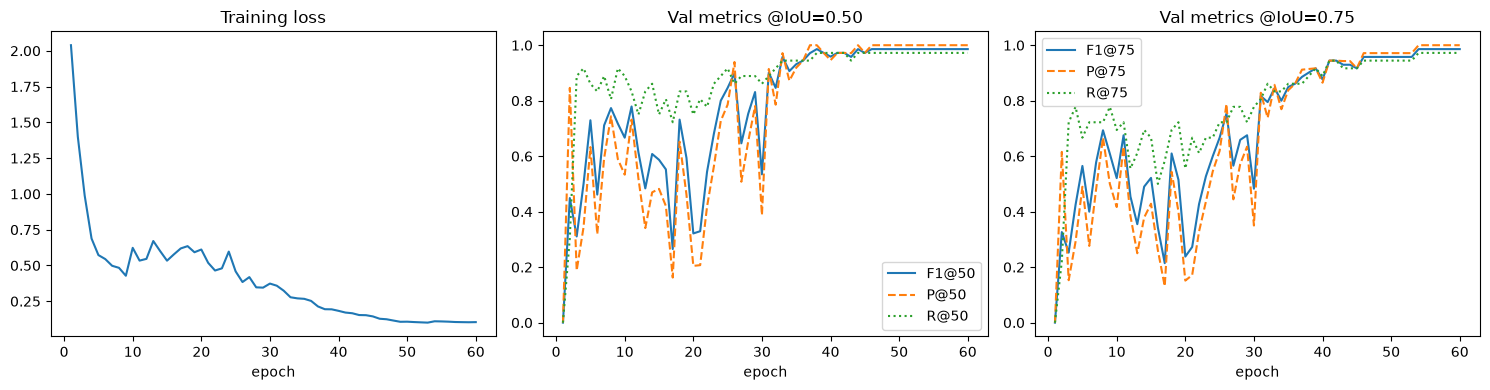

Best epoch: 38 | F1@50 = 0.986


In [ ]:
import pandas as pd

hist_path = RUN_DIR / f'{RUN_NAME}_history.json'
overfit_hist_path = RUN_DIR / 'overfit_history.json'

if hist_path.is_file():
      hist = pd.DataFrame(json.loads(hist_path.read_text()))
elif overfit_hist_path.is_file():
      hist = pd.DataFrame(json.loads(overfit_hist_path.read_text()))
elif 'h' in globals() and h:
      hist = pd.DataFrame(h)
else:
      raise FileNotFoundError(
            f'No training history found at {hist_path} or {overfit_hist_path}.'
      )

""" Plot training and validation metrics """
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

""" Plot training loss """
axes[0].plot(hist['epoch'], hist['loss'])
axes[0].set_title('Training loss'); axes[0].set_xlabel('epoch')

""" Plot validation metrics @IoU=0.50 and @IoU=0.75 """
axes[1].plot(hist['epoch'], hist['f1@50'],        label='F1@50')
axes[1].plot(hist['epoch'], hist['precision@50'], label='P@50', linestyle='--')
axes[1].plot(hist['epoch'], hist['recall@50'],    label='R@50', linestyle=':')
axes[1].set_title('Val metrics @IoU=0.50'); axes[1].legend(); axes[1].set_xlabel('epoch')

""" Plot validation metrics @IoU=0.75 """
axes[2].plot(hist['epoch'], hist['f1@75'],        label='F1@75')
axes[2].plot(hist['epoch'], hist['precision@75'], label='P@75', linestyle='--')
axes[2].plot(hist['epoch'], hist['recall@75'],    label='R@75', linestyle=':')
axes[2].set_title('Val metrics @IoU=0.75'); axes[2].legend(); axes[2].set_xlabel('epoch')

""" Finalize and save the plots """
plt.tight_layout()
plt.savefig(RUN_DIR / f'{RUN_NAME}_curves.png', dpi=120)
plt.show()
print('Best epoch:', hist.loc[hist['f1@50'].idxmax(), 'epoch'],
      '| F1@50 =', round(hist['f1@50'].max(), 3))

## 6 Threshold sweep on validation set

Load the best checkpoint, run inference once per NMS setting, then score across many score thresholds without re-running the model. Pick the score threshold that maximises F1@50.

In [14]:
""" Load best checkpoint """ 
checkpoint_paths = [
    RUN_DIR / f'{RUN_NAME}_best.pt',
    RUN_DIR / 'overfit_best.pt',
]
ckpt_path = next((path for path in checkpoint_paths if path.is_file()), None)
""" Find the first existing checkpoint """
if ckpt_path is None:
    raise FileNotFoundError(
        f'No best checkpoint found. Checked: {checkpoint_paths}. '
        'Run the training cell first.'
    )

ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=True)
print('Using checkpoint:', ckpt_path)
model = new_model()   # fresh model with correct arch
model.load_state_dict(ckpt['model'])
model = model.to(device).eval()
print('Loaded best checkpoint: epoch', ckpt['epoch'])

val_loader_eval = make_loader('val', augment=False)

NMS_GRID   = (0.6, 0.5, 0.4, 0.3)
SCORE_GRID = np.arange(0.30, 1.00, 0.05)

rows = []
""" Sweep over NMS and score thresholds """
for nms in NMS_GRID:
    print(f'  running NMS={nms} ...', end=' ')
    cache = collect(model, val_loader_eval, device, nms=nms)
    for thr in SCORE_GRID:
        m = metrics(cache, score_thr=float(thr))
        rows.append(dict(nms=nms, score_thr=round(float(thr), 2), **m))
    print('done')

sweep = pd.DataFrame(rows)
""" Save the sweep results to CSV """
sweep.to_csv(RUN_DIR / 'val_threshold_sweep.csv', index=False)
print('\nTop 10 by F1@50:')
print(sweep.nlargest(10, 'f1@50')[['nms', 'score_thr', 'f1@50', 'precision@50', 'recall@50']].to_string(index=False))

Using checkpoint: C:\Users\HPZ4G4Workstation\Documents\mTech\PVsys\PVsys_1\playground\runs\exp3\overfit_best.pt
Loaded best checkpoint: epoch 26
  running NMS=0.6 ... done
  running NMS=0.5 ... done
  running NMS=0.4 ... done
  running NMS=0.3 ... done


NameError: name 'pd' is not defined

In [ ]:
""" Plot precision-recall trade-off for each NMS setting """
fig, ax = plt.subplots(figsize=(8, 5))
for nms, grp in sweep.groupby('nms'):
    """ Sort the group by recall@50 for plotting """
    grp = grp.sort_values('recall@50')
    ax.plot(grp['recall@50'], grp['precision@50'], marker='.', label=f'NMS={nms}')
    """ Plot the precision-recall curve for this NMS setting """

""" Finalize the precision-recall plot """
ax.set_xlabel('Recall@50'); ax.set_ylabel('Precision@50')
ax.set_title('Precision-Recall curve (val) — vary score threshold')
ax.legend(); plt.tight_layout(); plt.show()

## 7 Test evaluation

In [ ]:
""" Choose score threshold / NMS from the validation sweep (best F1@50) """
best_row = sweep.loc[sweep['f1@50'].idxmax()]
CHOSEN = dict(
    score_thr = float(best_row['score_thr']),
    nms       = float(best_row['nms']),
)
SELECTION_RULE = 'max val F1@50 over NMS_GRID x SCORE_GRID'
print('Chosen:', CHOSEN)

""" Export val + test predictions in the shared format and evaluate with foodseg_common """
for split in ('val', 'test'):
    preds, sec = export_preds(model, split, nms=CHOSEN['nms'])
    fc.save_preds(preds, OUT_ROOT / f'maskrcnn_{split}.pkl',
                  meta=dict(model='Mask R-CNN', checkpoint=str(ckpt_path), sec_per_image=sec,
                            score_thr=CHOSEN['score_thr'], nms=CHOSEN['nms']))
    print(f'saved {split}: {len(preds)} images, {sec:.3f}s/img')

test_preds, test_meta = fc.load_preds(OUT_ROOT / 'maskrcnn_test.pkl')
test_m = fc.evaluate(test_preds, 'test', score_thr=CHOSEN['score_thr'])

result = {**test_m, **CHOSEN, 'rule': SELECTION_RULE, 'sec_per_image': test_meta['sec_per_image']}
(RUN_DIR / 'test_result.json').write_text(json.dumps(result, indent=2))

print('Test results:')
for k, v in result.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

## 8 Visualise test predictions

In [ ]:
""" Show predictions on test dataset (from the exported cache) """
thr = CHOSEN['score_thr']
sample_ids = random.sample(list(test_preds), min(6, len(test_preds)))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, sid in zip(axes.flat, sample_ids):
    img = fc.load_rgb(fc.image_path('test', sid))
    masks = fc.decode_kept(test_preds[sid], thr, max_masks=10)
    ax.imshow(fc.overlay(img, masks))
    ax.set_title(f'{sid}: {len(masks)} detections (thr={thr})', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 9 Save final checkpoint

In [ ]:
""" Ensure CHOSEN parameters are set """
assert CHOSEN['score_thr'] is not None, 'Complete Step 7 first'
"""Load the final model and update its configuration with chosen parameters."""
final = torch.load(ckpt_path, map_location='cpu', weights_only=True)
final['config'].update({
    'score_thr': CHOSEN['score_thr'],
    'nms':       CHOSEN['nms'],
    'selection_rule': SELECTION_RULE,
})
out = RUN_DIR / 'modelA_final.pt'
torch.save(final, out)
print('Saved:', out)
print('Contents:', list(final.keys()))

## 10 Zero-shot baseline (COCO-pretrained, no fine-tuning)

COCO-pretrained Mask R-CNN v2 with its original 91-class head, never trained on FoodSeg103.
Only needs sections 1–3 (sections 4–9 can be skipped).

COCO only has a handful of food classes, so two ways of turning its detections into class-agnostic
"food regions" are compared on the validation split:
- `food`: only the COCO food classes (banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake)
- `all_but_person_table`: every COCO class except person and dining table

Detections of different classes are merged with class-agnostic NMS. The label set, NMS and score threshold
are chosen on val; test is run once and saved to `outputs/maskrcnn_zeroshot_test.pkl` for `compare_models.ipynb`.

In [18]:
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2, MaskRCNN_ResNet50_FPN_V2_Weights

ZS_WEIGHTS = MaskRCNN_ResNet50_FPN_V2_Weights.COCO_V1
COCO_NAMES = ZS_WEIGHTS.meta['categories']   # list index == label id
COCO_FOOD = {COCO_NAMES.index(n) for n in ('banana', 'apple', 'sandwich', 'orange', 'broccoli',
                                           'carrot', 'hot dog', 'pizza', 'donut', 'cake')}
COCO_NOT_FOOD = {COCO_NAMES.index(n) for n in ('person', 'dining table')}
ZS_LABEL_SETS = {
    'food': COCO_FOOD,
    'all_but_person_table': set(range(1, len(COCO_NAMES))) - COCO_NOT_FOOD,
}
ZS_NMS_GRID = (0.5, 0.7)
ZS_SCORE_GRID = np.arange(0.05, 1.0, 0.05)

""" Pretrained model, unchanged head. Batch size 1 and 50 dets keep full-resolution mask pasting within 8 GB. """
zs_model = maskrcnn_resnet50_fpn_v2(
    weights=ZS_WEIGHTS,
    min_size=CFG['min_size'], max_size=CFG['max_size'],
    box_detections_per_img=50, box_score_thresh=0.05,
).to(device).eval()


@torch.no_grad()
def export_zeroshot(model, split, limit=None, mask_thr=0.5):
    """Run the COCO model over a split; keeps labels and boxes so detections can be filtered offline."""
    ds = FoodDataset(split, augment=False, min_area=CFG['min_area'], limit=limit, use_food_preprocess=False)
    loader = DataLoader(ds, batch_size=1, shuffle=False, collate_fn=collate_fn, num_workers=CFG['num_workers'])
    raw, t0 = {}, time.time()
    for imgs, targets in loader:
        out = model([i.to(device) for i in imgs])
        for img, pred, tgt in zip(imgs, out, targets):
            sid = ds.ids[int(tgt['image_id'])]
            h, w = img.shape[-2:]
            pm = (pred['masks'][:, 0] > mask_thr).cpu().numpy()
            raw[sid] = dict(h=int(h), w=int(w), rle=fc.encode_masks(pm),
                            scores=pred['scores'].cpu().numpy(),
                            labels=pred['labels'].cpu().numpy(),
                            boxes=pred['boxes'].cpu().numpy())
    return raw, (time.time() - t0) / max(1, len(raw))


def zs_filter(raw, label_set, nms_thr, max_dets=CFG['max_dets']):
    """Keep detections whose COCO label is in label_set, then class-agnostic NMS -> foodseg_common cache."""
    preds = {}
    for sid, p in raw.items():
        keep = [i for i, l in enumerate(p['labels']) if int(l) in label_set]
        if keep:
            k = torchvision.ops.nms(torch.as_tensor(p['boxes'][keep]), torch.as_tensor(p['scores'][keep]), nms_thr)
            keep = [keep[i] for i in k[:max_dets].tolist()]
        preds[sid] = dict(h=p['h'], w=p['w'], rle=[p['rle'][i] for i in keep],
                          scores=p['scores'][keep].astype(np.float32))
    return preds


print('Zero-shot model ready:', sum(p.numel() for p in zs_model.parameters()) / 1e6, 'M params')

Zero-shot model ready: 46.359409 M params


In [19]:
""" Validation: choose label set + NMS by AP, then the score threshold by F1@50 """
zs_raw_val, zs_sec_val = export_zeroshot(zs_model, 'val')
print(f'val: {len(zs_raw_val)} images, {zs_sec_val:.3f}s/img')

rows = []
for set_name, labels in ZS_LABEL_SETS.items():
    for nms in ZS_NMS_GRID:
        preds = zs_filter(zs_raw_val, labels, nms)
        sw = pd.DataFrame(fc.threshold_sweep(fc.build_iou_cache(preds, 'val'), ZS_SCORE_GRID))
        best = sw.loc[sw['f1@50'].idxmax()]
        rows.append(dict(label_set=set_name, nms=nms, **fc.coco_ap(preds, 'val'),
                         score_thr=float(best['score_thr']), f1_50=float(best['f1@50']),
                         preds_per_image=np.mean([len(p['rle']) for p in preds.values()])))

zs_sweep = pd.DataFrame(rows).sort_values('AP', ascending=False)
zs_sweep.to_csv(RUN_DIR / 'zeroshot_val_sweep.csv', index=False)
print(zs_sweep.to_string(index=False))

zs_best = zs_sweep.iloc[0]
ZS_CHOSEN = dict(label_set=zs_best['label_set'], nms=float(zs_best['nms']), score_thr=float(zs_best['score_thr']))
print('Chosen:', ZS_CHOSEN)

val: 1067 images, 0.445s/img
           label_set  nms       AP     AP50     AP75  AP_small  AP_medium  AP_large      AR1     AR10    AR100  score_thr    f1_50  preds_per_image
                food  0.7 0.068061 0.144818 0.058817  0.001000   0.022450  0.105203 0.096116 0.237528 0.265952       0.35 0.248807        11.178069
                food  0.5 0.067834 0.144701 0.058684  0.001001   0.022360  0.104382 0.096116 0.235485 0.262144       0.30 0.248679        10.913777
all_but_person_table  0.7 0.061012 0.142568 0.047143  0.000903   0.020879  0.092723 0.078462 0.251627 0.288625       0.60 0.260219        14.097470
all_but_person_table  0.5 0.059462 0.139494 0.045059  0.000905   0.020804  0.089618 0.078462 0.245675 0.275990       0.60 0.260337        13.432990
Chosen: {'label_set': 'food', 'nms': 0.7, 'score_thr': 0.35}


In [20]:
""" Test: export once with the val-chosen settings and evaluate """
zs_meta = dict(model='Mask R-CNN v2 COCO zero-shot', **ZS_CHOSEN)
zs_val_preds = zs_filter(zs_raw_val, ZS_LABEL_SETS[ZS_CHOSEN['label_set']], ZS_CHOSEN['nms'])
fc.save_preds(zs_val_preds, OUT_ROOT / 'maskrcnn_zeroshot_val.pkl', meta=dict(zs_meta, sec_per_image=zs_sec_val))

zs_raw_test, zs_sec_test = export_zeroshot(zs_model, 'test')
zs_test_preds = zs_filter(zs_raw_test, ZS_LABEL_SETS[ZS_CHOSEN['label_set']], ZS_CHOSEN['nms'])
fc.save_preds(zs_test_preds, OUT_ROOT / 'maskrcnn_zeroshot_test.pkl', meta=dict(zs_meta, sec_per_image=zs_sec_test))

zs_result = {**fc.evaluate(zs_test_preds, 'test', score_thr=ZS_CHOSEN['score_thr']), **zs_meta,
             'sec_per_image': zs_sec_test}
(RUN_DIR / 'zeroshot_test_result.json').write_text(json.dumps(zs_result, indent=2))

print('Zero-shot test results:')
for k, v in zs_result.items():
    print(f'  {k}: {v:.4f}' if isinstance(v, float) else f'  {k}: {v}')

Zero-shot test results:
  n_images: 1069
  score_thr: 0.3500
  AP: 0.0749
  AP50: 0.1546
  AP75: 0.0632
  AP_small: 0.0011
  AP_medium: 0.0305
  AP_large: 0.1133
  AR1: 0.0998
  AR10: 0.2403
  AR100: 0.2653
  precision@50: 0.2385
  recall@50: 0.2864
  f1@50: 0.2603
  precision@75: 0.1488
  recall@75: 0.1787
  f1@75: 0.1624
  gt_coverage_mean: 0.4274
  gt_coverage_at50: 0.4211
  fg_iou_mean: 0.5072
  fg_iou_pixel: 0.4903
  preds_per_image: 4.4004
  model: Mask R-CNN v2 COCO zero-shot
  label_set: food
  nms: 0.7000
  sec_per_image: 0.3849


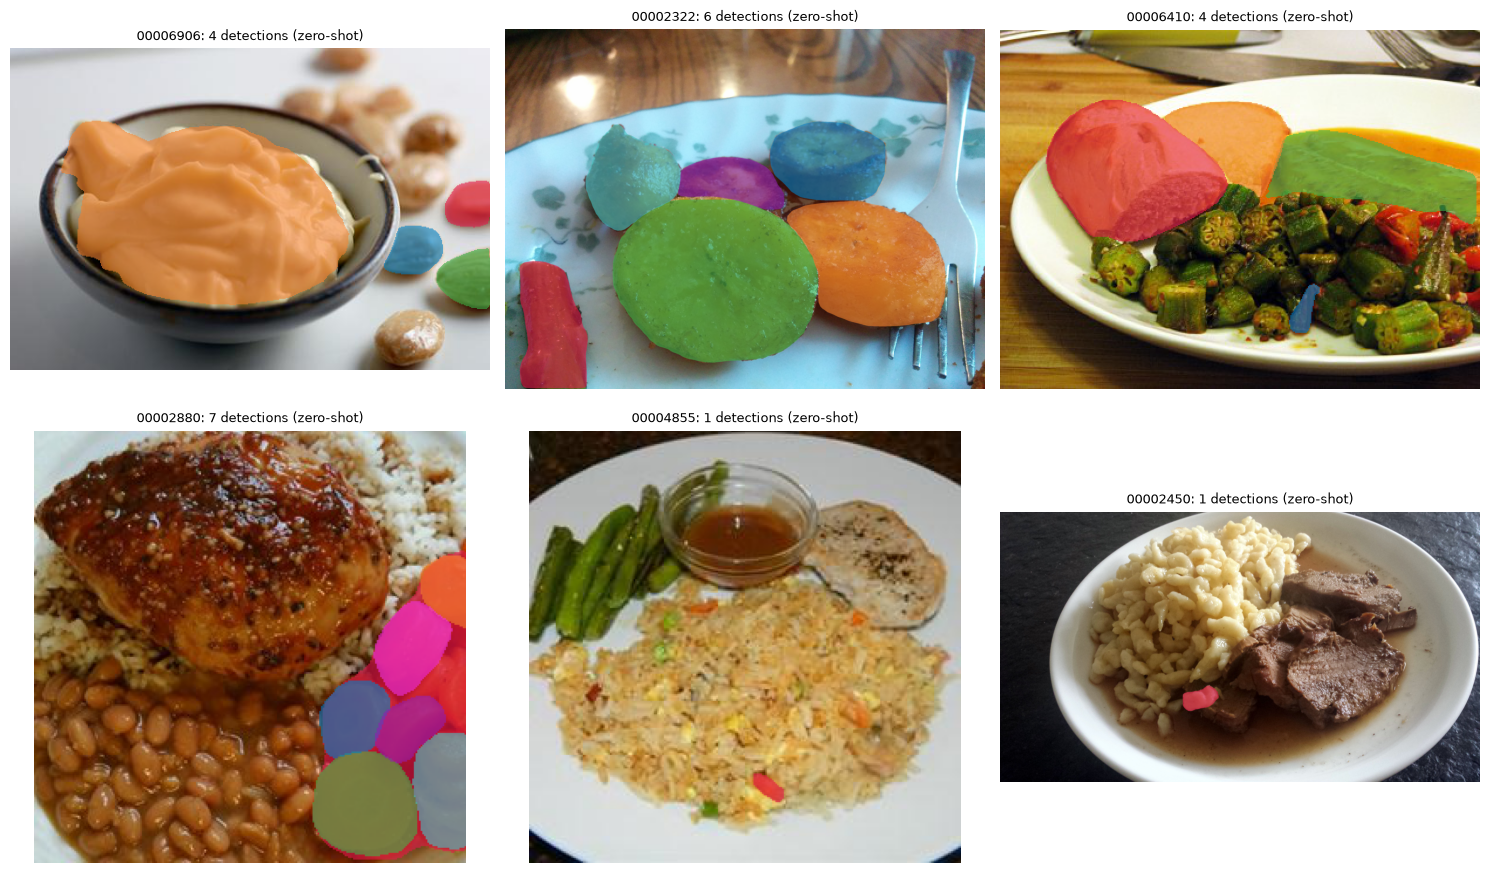

In [21]:
""" Show zero-shot predictions on test images """
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, sid in zip(axes.flat, random.sample(list(zs_test_preds), min(6, len(zs_test_preds)))):
    img = fc.load_rgb(fc.image_path('test', sid))
    masks = fc.decode_kept(zs_test_preds[sid], ZS_CHOSEN['score_thr'], max_masks=10)
    ax.imshow(fc.overlay(img, masks))
    ax.set_title(f'{sid}: {len(masks)} detections (zero-shot)', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()